# Procesar los registros de entrenamiento y validación de la frontera

**Pregunta:** ¿Qué respaldan los registros de entrenamiento y validación, y dónde termina la inferencia?

**Nivel:** Un método aplicado y análisis de evidencia con límites explícitos de afirmación.

## Objetivos

Esta lección lee el resumen confirmado y sin rutas locales del entrenamiento de cinco integrantes, además de las 200 filas de su reproducción solo de validación. Comprueba identidad de partición y commit de origen, recalcula resúmenes de completitud, objetivo y cobertura, inspecciona las historias de selección de checkpoints y grafica resultados por caso junto con sus límites. Los registros conservan salidas reales de la canalización del producto sin pesos del modelo ni rutas específicas del equipo. Esta lección procesa evidencia: no vuelve a entrenar el actor, recrea los resultados de prueba perdidos ni puntúa casos del producto.

## Preparación

Usa NumPy y Matplotlib en las versiones fijadas para el entorno de cuadernos. Los registros y el manifiesto congelado están confirmados bajo la carpeta de diseño de la política, por lo que la lección funciona desde un clon nuevo sin acceder al disco original de entrenamiento. No reemplaces un registro ausente por valores copiados ni por una ejecución posterior. Su esquema JSON, digests y commit de origen son parte de la procedencia. Un fallo de integridad detiene el análisis porque una sustitución no trazada volvería imposible auditar las cifras mostradas.

Comando para preparar el entorno:

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2
```

In [1]:
# Carga registros de procedencia y funciones de partición del producto.
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline").is_dir())
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.frontier_splits import build_split_manifest, manifest_sha256
from pipeline.model.frontier_policy import validate_split_manifest

RECORDS = ROOT / "docs/design/features/learned-frontier/records"
summary = json.loads((RECORDS / "training-summary.json").read_text(encoding="utf-8"))
diagnostic = json.loads((RECORDS / "validation-diagnostic.json").read_text(encoding="utf-8"))
manifest = json.loads(
    (ROOT / "docs/design/features/learned-frontier/split-manifest.json").read_text(encoding="utf-8")
)["manifest"]
from pipeline.model.frontier_data import generate_graph, FEATURE_NAMES
from pipeline.model.frontier_policy import (
    FeatureNormalizer,
    feasible_frontier,
    precedence_frontier,
    replay_frontier_policy,
    validate_schedule,
)
import importlib.metadata

print({name: importlib.metadata.version(name) for name in ("oreblocks", "numpy", "matplotlib")})


{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2'}


## Datos

El resumen de entrenamiento omite ubicaciones de checkpoints y conserva el digest del recibo original, commit de origen, motor, cinco semillas de integrante, hashes de checkpoints seleccionados y finales, historias de transiciones y límites de cómputo. El diagnóstico guarda una fila por semilla declarada de validación, con familia, tamaño, cantidad asignada, objetivo normalizado, dos fracciones de cobertura y estado de validación independiente. El manifiesto congelado separa entrenamiento, validación y prueba. Ninguna fila de prueba aparece en el diagnóstico y aquí no se abre ninguno de los trece escenarios del producto.

## Método

Primero reconstruye las particiones con el generador del producto y valida que sean disjuntas. Vincula cada semilla del diagnóstico con las filas de validación del manifiesto y verifica familia, tamaño y estado de comprobación independiente. Después recalcula agregados descriptivos desde las filas individuales, en vez de confiar en el encabezado del resumen. Para cada integrante conserva la historia de validación y el digest del checkpoint seleccionado; un recibo de entrenamiento completo no establece por sí mismo una política útil. Los gráficos mantienen planes vacíos y cobertura cero. Ningún umbral convierte estas observaciones de validación en una afirmación de prueba.

$$NPV=\sum_{b\in S}\frac{v_b}{(1+d)^{p_b}}.$$

$$c^+=\frac{\sum_{b\in S}\max(v_b,0)}{\sum_b\max(v_b,0)}.$$

El objetivo y la cobertura de valor positivo responden preguntas distintas; los registros informan ambas.

Reconstruye las particiones congeladas y valida que sean disjuntas.

In [2]:
# Reconstruye y valida el manifiesto exacto antes de leer las filas de resultados.
case_ids = manifest["product_case_ids"]
rebuilt = build_split_manifest(case_ids)
validate_split_manifest(manifest)
assert manifest_sha256(rebuilt) == summary["split_sha256"] == diagnostic["split_sha256"]
assert summary["training_source_commit"] == diagnostic["training_source_commit"]
print(
    {
        "split_sha256": summary["split_sha256"],
        "source_commit": summary["training_source_commit"],
        "members": len(summary["members"]),
    }
)


{'split_sha256': '18860c8a361576ba924ec95fd5dfe9d58c8a37a3466a1c17bb9765ddfc81350c', 'source_commit': '4aa49f4e72b2563d652a5636f69c2c5a5582db00', 'members': 5}


Vincula cada caso diagnóstico con su semilla y tamaño congelados.

In [3]:
# Vincula cada fila diagnóstica con su semilla, familia y tamaño congelados.
expected = {row["seed"]: row for row in manifest["validation"]}
rows = diagnostic["case_results"]
for row in rows:
    frozen = expected[row["seed"]]
assert diagnostic["all_schedules_independently_validated"]


Recalcula las distribuciones informadas desde las filas por caso.

In [4]:
# Recalcula agregados desde los casos y conserva los planes vacíos.
npv = np.asarray([row["normalized_npv"] for row in rows], dtype=float)
value_coverage = np.asarray([row["positive_value_coverage"] for row in rows], dtype=float)
assigned = np.asarray([row["assigned_blocks"] for row in rows], dtype=int)
computed = {
    "cases": len(rows),
    "nonempty_fraction": float(np.mean(assigned > 0)),
    "mean_assigned_blocks": float(assigned.mean()),
    "median_npv": float(np.median(npv)),
    "median_value_coverage": float(np.median(value_coverage)),
    "minimum_npv": float(np.min(npv)),
    "maximum_npv": float(np.max(npv)),
}
print(computed)


{'cases': 200, 'nonempty_fraction': 0.49, 'mean_assigned_blocks': 1.84, 'median_npv': 0.0, 'median_value_coverage': 0.0, 'minimum_npv': -0.0015200422109756784, 'maximum_npv': 0.052875241354758566}


Inspecciona las historias de selección como registros de entrenamiento.

In [5]:
# Resume las historias de validación sin convertirlas en evidencia de prueba.
for member in summary["members"]:
    history = member["validation_history"]
print(
    [
        {
            "seed": member["seed"],
            "transitions": member["transitions"],
            "stop": member["stop_reason"],
            "events": len(member["validation_history"]),
        }
        for member in summary["members"]
    ]
)


[{'seed': 1103, 'transitions': 40960, 'stop': 'cpu-cap', 'events': 1}, {'seed': 2207, 'transitions': 45056, 'stop': 'cpu-cap', 'events': 2}, {'seed': 3301, 'transitions': 61440, 'stop': 'cpu-cap', 'events': 2}, {'seed': 4409, 'transitions': 53248, 'stop': 'cpu-cap', 'events': 2}, {'seed': 5519, 'transitions': 53248, 'stop': 'cpu-cap', 'events': 2}]


Regenera un grafo de validación desde su semilla congelada; solo verifica el contrato público de entrada.

In [6]:
# Regenera un grafo de validación desde su semilla congelada; solo verifica el contrato público de entrada.
sample = rows[0]
example = generate_graph(sample["seed"], sample["family"], sample["size"])
print(
    {
        "seed": sample["seed"],
        "family": example.family,
        "size": len(example.instance.values),
        "features": FEATURE_NAMES,
    }
)


{'seed': 200000, 'family': 'crosscut', 'size': 32, 'features': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count')}


Ajusta un normalizador pequeño solo con grafos de entrenamiento y conserva su digest y orden.

In [7]:
# Ajusta un normalizador pequeño solo con grafos de entrenamiento y conserva su digest y orden.
train_graphs = [generate_graph(row["seed"], row["family"], row["size"]) for row in manifest["train"][:8]]
train_matrix = np.vstack([graph.node_features for graph in train_graphs])
normalizer = FeatureNormalizer.fit(train_matrix, FEATURE_NAMES, declared_features=FEATURE_NAMES)
print({"training_rows": normalizer.train_rows, "normalizer_sha256": normalizer.sha256})


{'training_rows': 368, 'normalizer_sha256': 'd4aab3f7fd25827c85fe0841c36bff0e7a2c4a6bda2a3ae82407d61828ba247d'}


Inspecciona un estado de decisión vacío sin puntuar los resultados guardados de validación.

In [8]:
# Inspecciona un estado de decisión vacío sin puntuar los resultados guardados de validación.
ready = precedence_frontier(example.instance, (), 0)
feasible = feasible_frontier(example.instance, (), 0)
print({"ready": len(ready), "feasible": len(feasible), "subset": set(feasible).issubset(ready)})


{'ready': 1, 'feasible': 1, 'subset': True}


Reproduce mecánica transparente y valídala de forma independiente; no es un resultado del registro.

In [9]:
# Reproduce mecánica transparente y valídala de forma independiente; no es un resultado del registro.
score = lambda block, period, assigned: float(example.instance.values[block]) if block >= 0 else -1.0
mechanics_result = replay_frontier_policy(example.instance, score, tonnage=example.tonnage)
print(
    {
        "assignments": len(mechanics_result.assignments),
        "validated_npv": validate_schedule(example.instance, mechanics_result.assignments),
    }
)


{'assignments': 2, 'validated_npv': 0.9884496550171686}


## Comparación

La historia de entrenamiento y la reproducción posterior de validación responden preguntas distintas. Los eventos de validación seleccionaron checkpoints, por lo que examinarlos forma parte de seleccionar el modelo. La reproducción posterior comprueba políticas supervivientes en esa misma partición y con su validador independiente. La concordancia entre ambas vistas ayuda a depurar, pero no crea una muestra independiente. La prueba sintética de una sola ejecución no retuvo resultados por caso y el registro de partición impide repetirla. Los casos de producto siguen sin abrirse. Por eso comparamos registros y estados de evidencia, no desempeño entre políticas.

## Evidencia

La primera figura muestra cada caso de validación y conserva los planes sin asignaciones. La segunda resume finalización y cobertura en la partición reutilizada. Que el validador apruebe significa que el plan emitido cumple las restricciones declaradas; no significa que la programación sea completa. La mediana nula de cobertura de valor y las asignaciones escasas diagnostican el problema actual de utilidad. Como los checkpoints se eligieron con estos mismos casos, las estadísticas son descriptivas y posteriores a la selección. No justifican superioridad, generalización ni un selector de planificación para usuarios.

El registro conserva deliberadamente cada semilla y tamaño de grafo en vez de distribuir solo una tabla agregada. Así, el lector puede auditar cruces, reproducir cuantiles, inspeccionar valores extremos y detectar una fila ausente sin adivinar cómo se calculó el resumen. Los hashes vinculan el resumen público con su recibo original externo y la partición congelada. El diagnóstico basta para sus cálculos descriptivos, mientras que los checkpoints privados no son necesarios para reproducirlos.

El resumen omite deliberadamente las trayectorias estado-acción y los pesos entrenados. El lector puede verificar la pertenencia de los registros, recalcular los valores descriptivos publicados e inspeccionar la variación entre casos, pero no reconstruir las elecciones de la política solo con este registro compacto. Esa distinción importa para la reproducibilidad: la lección reproduce el análisis de la evidencia conservada, no la evaluación perdida. El registro de particiones también muestra que volver a reproducir la validación repetiría datos de selección en vez de generar evidencia nueva.

Grafica cada caso de validación, incluidos los planes vacíos.

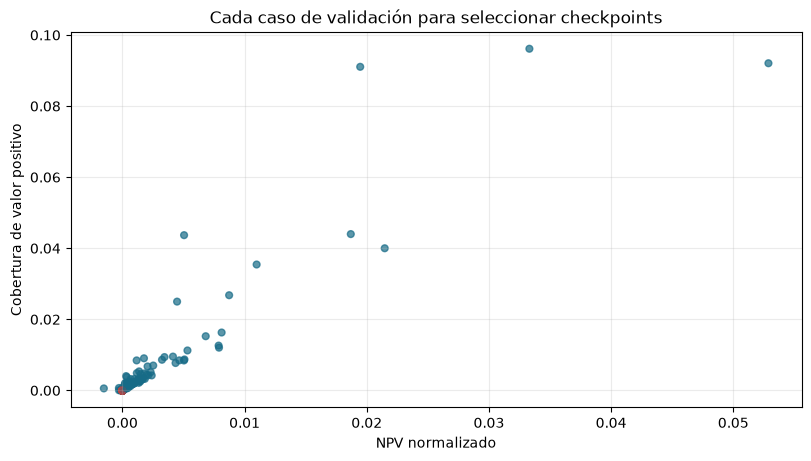

In [10]:
# Grafica cada caso e identifica directamente los resultados sin cobertura.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.scatter(npv, value_coverage, c=np.where(assigned > 0, "#176B87", "#B84444"), alpha=0.7, s=24)
ax.set(
    xlabel="NPV normalizado",
    ylabel="Cobertura de valor positivo",
    title="Cada caso de validación para seleccionar checkpoints",
)
ax.grid(alpha=0.25)
plt.show()


Los puntos graficados son las filas originales por caso. Su dispersión importa porque un resumen central oculta planes vacíos y resultados negativos. Los puntos rojos marcan casos sin bloques asignados, mientras que la posición vertical conserva la cobertura de valor positivo. La vista conjunta muestra dónde un plan factible aún deja valor sin extraer.

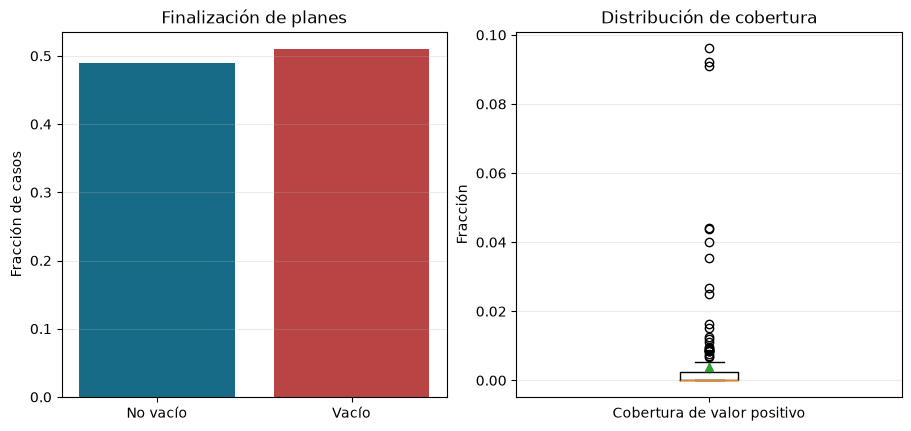

In [11]:
# Grafica la finalización y cobertura junto a su rango observado completo.
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), constrained_layout=True)
axes[0].bar(
    ["No vacío", "Vacío"], [np.mean(assigned > 0), np.mean(assigned == 0)], color=["#176B87", "#B84444"]
)
axes[0].set(ylabel="Fracción de casos", title="Finalización de planes")
axes[1].boxplot([value_coverage], tick_labels=["Cobertura de valor positivo"], showmeans=True)
axes[1].set(ylabel="Fracción", title="Distribución de cobertura")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.show()


El histograma conserva ceros y valores negativos en vez de centrarse solo en los casos exitosos. Su distribución pertenece a la partición reutilizada para seleccionar checkpoints: diagnostica la ejecución guardada, no da una estimación independiente. Léelo junto al gráfico por caso para conservar contexto de grupos y valores extremos.

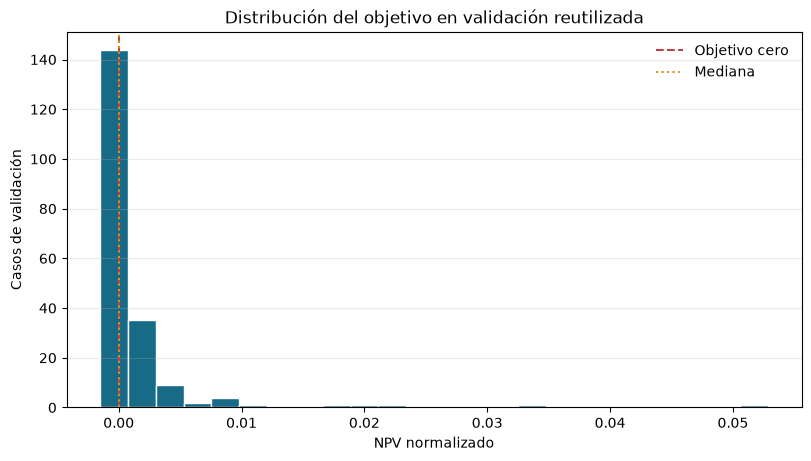

In [12]:
# Grafica objetivos normalizados con referencias de mediana y cero.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(npv, bins=24, color="#176B87", edgecolor="white")
ax.axvline(0, color="#B84444", linestyle="--", label="Objetivo cero")
ax.axvline(np.median(npv), color="#D79222", linestyle=":", label="Mediana")
ax.set(
    xlabel="NPV normalizado",
    ylabel="Casos de validación",
    title="Distribución del objetivo en validación reutilizada",
)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.show()


El histograma conserva los 200 objetivos de validación, incluidos valores negativos y ceros. Las líneas verticales marcan cero y la mediana de la muestra. Su forma describe solo estos casos guardados de selección de checkpoint: la partición se reutilizó después de seleccionar checkpoints, por lo que la gráfica es diagnóstica y no respalda una afirmación de desempeño en prueba independiente.

## Resultados

Lee la media junto con mediana, rango, fracción de casos no vacíos, cantidad de bloques y ambas coberturas. Una media positiva pequeña puede coexistir con una mediana cero si la mayoría de las ejecuciones no devuelve bloques con valor y unos pocos casos concentran el agregado. Las historias por integrante muestran también el presupuesto finito y los checkpoints de validación reales. Un hash de checkpoint o una curva de pérdida finita no es un criterio de aceptación de planificación minera. Los resultados reservados ausentes siguen como no disponibles; no se reconstruyen desde el comportamiento del modelo ni se reemplazan con filas de validación.

**Respuesta:** El ejemplo de 200 validation records respalda los cálculos presentados, y su estado solo de validación limita la conclusión.

## Resumen

El procesamiento es reproducible y conserva la evidencia negativa. Las salidas actuales respaldan afirmaciones sobre finalización de entrenamiento limitada, procedencia de checkpoints, validación independiente en la partición de validación reutilizada y cobertura escasa por caso. No respaldan un resultado de desempeño reservado. La recuperación requiere un protocolo versionado revisado, una nueva partición disjunta por semilla y familia, y salidas persistidas por caso antes de abrir escenarios del producto. Usa esta lección para explicar el límite y auditar los diagnósticos; no la presentes como benchmark final ni artefacto de despliegue.

### Sensibilidad y límites

Primero comprueba si el resumen descriptivo depende de pocos casos. Recalcula medianas, cuartiles, mínimo y máximo, fracción no vacía y ambas coberturas por familia y tamaño de grafo. Grafica la distribución empírica conservando ceros y valores negativos. Un remuestreo de estas 200 filas cuantificaría variación condicionada a esta muestra de validación reutilizada; no elimina el sesgo de selección del checkpoint ni produce una estimación de prueba independiente. Declara la unidad y semilla del remuestreo si agregas ese diagnóstico, y no lo llames intervalo de confianza para futuros yacimientos.

Las cinco historias de entrenamiento también deben leerse como registros con recursos limitados. Compara por miembro cantidad de transiciones, razón de término, frecuencia de validación, checkpoint seleccionado y checkpoint final. Un miembro que agota un límite de CPU puede tener un recibo válido, pero completar el trabajo no demuestra que el plan sea útil. Las entradas ausentes o malformadas deben fallar la comprobación de integridad, no completarse desde otro miembro. El indicador del validador por caso responde si la asignación almacenada satisface las restricciones implementadas; no certifica los supuestos de entrada ni el modelo económico. Estos registros carecen de comparador independiente, resultados de prueba intactos y datos de yacimientos operacionales. Conserva esas ausencias en cada título, pie de figura y resumen.

Interpreta cada agregado junto con su denominador. Una media de 200 filas deja de ser interpretable si se omitieron filas, por eso concilia los IDs con el manifiesto antes de graficar. Busca IDs duplicados, campos ausentes, valores no finitos y pertenencia inesperada a particiones. Para resúmenes por categoría, informa conteos y porcentajes: un grupo pequeño puede parecer más convincente de lo que es. Mantén las gráficas descriptivas e incluye el código de procesamiento junto a las filas fuente. Si un protocolo futuro introduce ponderaciones o exclusiones, versiona la regla, presenta también resultados sin ponderar y conserva qué casos cambiaron de estado. No ajustes umbrales de decisión usando estas observaciones reutilizadas para luego presentar el resultado como una estimación de desempeño independiente.

### Uso con datos propios

Antes de recopilar resultados, define un esquema de casos estable con ID opaco, digest de datos fuente, familia del yacimiento, tamaño, partición, semilla, digest de configuración, digest del checkpoint y resultados explícitos. Congela particiones y protocolo en un documento versionado y revisado. Mantén una partición de prueba nueva, disjunta de los casos de ajuste y validación, y escribe una fila durable de registro antes de procesar cada caso. Persiste el resultado inmediatamente, incluso fallas y mensajes del validador; al reiniciar, omite filas completadas según su hash, sin recalcularlas implícitamente. Nunca reemplaces un resultado de prueba no disponible por uno de validación.

Elige la línea base antes de abrir resultados de prueba y ejecuta ambos métodos con entradas y supuestos de recursos idénticos. Recalcula objetivo y cobertura desde el plan canónico y el caso original; compara resultados pareados mediante un análisis predefinido. Registra datos faltantes, advertencias, exclusiones y versiones junto con las métricas. Publica datos por caso sanitizados suficientes para reproducir los agregados, y conserva fuentes restringidas y pesos bajo sus controles de acceso. Separa validación del software, evidencia científica, aceptación operacional y aprobación de publicación. Esta lección solo demuestra procesamiento de registros; los datos propios requieren procedencia, protocolo aprobado y evaluación independiente antes de sustentar afirmaciones empíricas.

## Referencias

El SDD y los registros de ejecución se mantienen en el repositorio de PhaseFlow. El artículo de gradiente de política describe la familia del optimizador, pero no respalda afirmaciones empíricas sobre esta política de planificación. Los conteos, distribuciones y resúmenes se recalculan desde los registros JSON confirmados.

- Método de gradiente de política: https://arxiv.org/abs/1707.06347
- Optimizador adaptativo: https://arxiv.org/abs/1412.6980
- Formulación de planificación a cielo abierto: https://doi.org/10.1287/inte.2013.0731
- Implementación y registros: https://github.com/fsantibanezleal/CAOS_PhaseFlow